# Trabajo del grupo 6, datos de las 5 grandes ligas europeas del fútbol
Alejandro Álvarez Segoviano e Ivo Reguero Ferrer

# 0. Importamos librerías

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

In [2]:
'''
ruta = Path().resolve().parent
ruta = ruta / "data" / "fulbo.csv"
ruta
''' # Se cambia, quita o deja en funcion de como pida leer los datos, del directorio directo, otra carpeta o etc...

PosixPath('/data/fulbo.csv')

In [5]:
ruta = "fulbo.csv"

# 1. Primer vistazo a los datos y EDA

## 1.1 Mirada inicial

Vamos a comenzar leyendo los datos, observando de cuántas observaciones disponemos, cuántos atributos y de qué naturaleza, previo a la modelización para entender mejor la naturaleza de ellas, cómo se relacionan y si presentan limitaciones o sesgos, para hallar de que tipo son.

In [8]:
df = pd.read_csv(ruta,header=1,index_col="Rk") # para no agrupar por el tipo de variable

In [9]:
df.head()

,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,...,PKatt,CrdY,CrdR,Gls.1,Ast.1,G+A.1,G-PK.1,G+A-PK,Matches,-9999
Rk,,,,,,,,,,,,,,,,,,,,,
1,Brenden Aaronson,us USA,MFFW,Leeds United,eng Premier League,24.0,2000.0,37,30,2449,...,0,3,0,0.15,0.18,0.33,0.15,0.33,Matches,5bc43860
2,Jerome Abbey,eng ENG,MF,Wolves,eng Premier League,15.0,2009.0,1,0,17,...,0,0,0,0.00,0.00,0.00,0.00,0.00,Matches,4f504fcc
3,Zach Abbott,eng ENG,DF,Nottingham,eng Premier League,19.0,2006.0,3,2,164,...,0,0,0,0.00,0.00,0.00,0.00,0.00,Matches,c103921a
4,Jones El-Abdellaoui,ma MAR,MFFW,Celta Vigo,es La Liga,19.0,2006.0,22,4,681,...,0,0,0,0.26,0.00,0.26,0.26,0.26,Matches,29dd3b2e
5,Himad Abdelli,dz ALG,MF,Marseille,fr Ligue 1,25.0,1999.0,8,1,138,...,0,1,0,0.00,0.00,0.00,0.00,0.00,Matches,7978cbf0


In [10]:
print(f"Disponemos de {df.shape[0]} jugadores y {df.shape[1]} atributos.")

Disponemos de 2839 jugadores y 26 atributos.


Esos 27 atributos son los siguientes :

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2839 entries, 0 to 2838
Data columns (total 27 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Rk       2839 non-null   int64  
 1   Player   2839 non-null   object 
 2   Nation   2836 non-null   object 
 3   Pos      2839 non-null   object 
 4   Squad    2839 non-null   object 
 5   Comp     2839 non-null   object 
 6   Age      2837 non-null   float64
 7   Born     2837 non-null   float64
 8   MP       2839 non-null   int64  
 9   Starts   2839 non-null   int64  
 10  Min      2839 non-null   int64  
 11  90s      2839 non-null   float64
 12  Gls      2839 non-null   int64  
 13  Ast      2839 non-null   int64  
 14  G+A      2839 non-null   int64  
 15  G-PK     2839 non-null   int64  
 16  PK       2839 non-null   int64  
 17  PKatt    2839 non-null   int64  
 18  CrdY     2839 non-null   int64  
 19  CrdR     2839 non-null   int64  
 20  Gls.1    2839 non-null   float64
 21  Ast.1    2839 

Algunos atributos tienen nulos, de igual forma cada variable individualmente será revisada después por si hay nulos codificados.

La página web de la que provienen los datos posee un glosario que usaremos para poder explicar qué significa cada dato, en la siguiente sección lo usaremos.

## 1.2 Diccionario De Atributos

In [13]:
diccionario = {
    "Identificación": [
        ("Rk", "Posición en la tabla de FBref (sin valor analítico)"),
        ("Player", "Nombre del jugador"),
        ("Nation", "Nacionalidad (código de 3 letras, p. ej. es ESP)"),
        ("Pos", "Posición: GK, DF, MF, FW; puede combinar varias (MF,FW)"),
        ("Squad", "Club"),
        ("Comp", "Liga / competición"),
        ("Age", "Edad al inicio de la temporada"),
        ("Born", "Año de nacimiento"),
    ],
    "Participación": [
        ("MP", "Partidos jugados"),
        ("Starts", "Partidos como titular"),
        ("Min", "Minutos jugados"),
        ("90s", "Minutos / 90 (denominador de las tasas por 90)"),
    ],
    "Producción ofensiva (totales)": [
        ("Gls", "Goles"),
        ("Ast", "Asistencias"),
        ("G+A", "Goles + asistencias"),
        ("G-PK", "Goles sin contar penaltis"),
        ("PK", "Penaltis marcados"),
        ("PKatt", "Penaltis intentados"),
    ],
    "Disciplina": [
        ("CrdY", "Tarjetas amarillas"),
        ("CrdR", "Tarjetas rojas"),
    ],
    "Por 90 minutos (el sufijo .1 lo añade pandas)": [
        ("Gls.1", "Goles por 90 min"),
        ("Ast.1", "Asistencias por 90 min"),
        ("G+A.1", "Goles + asistencias por 90 min"),
        ("G-PK.1", "Goles sin penalti por 90 min"),
        ("G+A-PK", "(Goles sin penalti + asistencias) por 90 min"),
    ],
    "Otras": [
        ("Matches", "Enlace al detalle partido a partido (sin valor analítico)"),
        ("-9999", "Sin identificar. Hipótesis: ID de jugador; verificar con nunique()"),
    ],
}

FONT = "18px"   # cambia aquí el tamaño

html = f"<div style='font-size:{FONT}'>"
html += "<h2>Diccionario de variables (FBref · Standard Stats)</h2>"
for seccion, filas in diccionario.items():
    html += f"<h3>{seccion}</h3><table style='border-collapse:collapse;width:100%'>"
    html += "<tr><th style='text-align:left;padding:8px;border-bottom:2px solid #888'>Variable</th>"
    html += "<th style='text-align:left;padding:8px;border-bottom:2px solid #888'>Descripción</th></tr>"
    for var, desc in filas:
        html += (f"<tr><td style='padding:8px;border-bottom:1px solid #ccc'><code>{var}</code></td>"
                 f"<td style='padding:8px;border-bottom:1px solid #ccc'>{desc}</td></tr>")
    html += "</table>"

display(HTML(html))

Variable,Descripción
Rk,Posición en la tabla de FBref (sin valor analítico)
Player,Nombre del jugador
Nation,"Nacionalidad (código de 3 letras, p. ej. es ESP)"
Pos,"Posición: GK, DF, MF, FW; puede combinar varias (MF,FW)"
Squad,Club
Comp,Liga / competición
Age,Edad al inicio de la temporada
Born,Año de nacimiento
Variable,Descripción
MP,Partidos jugados


## 1.3 Calidad del dato

En este apartado vamos a evaluar la calidad de los datos, hablando en castellano esto es asegurarnos los datos sean coherentes, no estén duplicados (principalmente para evitar leakage), tratar posibles nulos entre otras situaciones.

Se comenzará analizando la presencia de nulos en el dataset

In [19]:
df.isnull().sum()

,0
Player,0
Nation,3
Pos,0
Squad,0
Comp,0
Age,2
Born,2
MP,0
Starts,0
Min,0


Se presencian nulos en las variables Age, Born y Nation

In [21]:
df[df["Nation"].isnull()]

,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,...,PKatt,CrdY,CrdR,Gls.1,Ast.1,G+A.1,G-PK.1,G+A-PK,Matches,-9999
Rk,,,,,,,,,,,,,,,,,,,,,
1699,Nathan Mbala,NaN,MFFW,Metz,fr Ligue 1,17.0,2008.0,13,4,441,...,0,0,0,0.41,0.41,0.82,0.41,0.82,Matches,42754695
2005,Luis Orejuela,NaN,DF,Mallorca,es La Liga,NaN,NaN,1,1,90,...,0,0,0,0.00,0.00,0.00,0.00,0.00,Matches,18e70be1
2631,Yael Trepy,NaN,FW,Cagliari,it Serie A,NaN,NaN,8,0,91,...,0,0,0,0.99,0.00,0.99,0.99,0.99,Matches,20c36c00


Apreciamos son tres casos a priori aislados, a excepción de los casos de Luis Orejuela y Yael Trepy, donde la falta de la fecha de nacimiento y edad tiene sentido, ya que a partir de una se podría estimar un proxy de la otra, sin embargo al carecer de ambas esa información se pierde

Debido a que son solo tres filas con faltantes la información faltante ha sido buscada y va a ser imputada.

Para el caso de Nathan Mbala este nulo tiene un significado, dado que al inspeccionar en internet hay informacion que se contradice, por una parte algunas páginas le atribuyen nacionalidad francesa mientras que otras le atribuyen nacionalidad de la república del congo, incluso llegan a contradecirse de en que lugar nació, por lo que se va a dejar como nulo para no introducir información no verificada

In [38]:
df.loc[df['Player'] == 'Luis Orejuela', ['Nation', 'Age', 'Born']] = ['es ESP', 18, 2007]
df.loc[df['Player'] == 'Yael Trepy', ['Nation', 'Age', 'Born']] = ['fr FRA', 19, 2006]

In [39]:
df.isnull().sum()

,0
Player,0
Nation,1
Pos,0
Squad,0
Comp,0
Age,0
Born,0
MP,0
Starts,0
Min,0


Una vez acabados con los nulos, se pasa a investigar la presencia de duplicados

In [43]:
# Filas completamente idénticas
print("Filas duplicadas exactas:", df.duplicated().sum())

# Mismo nombre pero ID distinto (posibles homónimos)
por_nombre = df.groupby('Player')['-9999'].nunique()
homonimos = por_nombre[por_nombre > 1]
print("Nombres compartidos por IDs distintos:", len(homonimos))


Filas duplicadas exactas: 0
Nombres compartidos por IDs distintos: 4


¿Cuántos de ellos son la misma persona y cuantos son solo el mismo nombre?

In [46]:
equipos = df.groupby('-9999')['Squad'].nunique()
ids_traspasados = equipos[equipos > 1].index

traspasados = (df[df['-9999'].isin(ids_traspasados)]
               .sort_values(['-9999', 'Min'], ascending=[True, False]))

print("Jugadores en más de un equipo:", len(ids_traspasados))
print("Filas implicadas:", len(traspasados))

resumen = (traspasados.groupby(['-9999', 'Player'])
           .apply(lambda g: ' → '.join(f"{s} ({m} min)" for s, m in zip(g['Squad'], g['Min'])))
           .reset_index(name='equipos'))
resumen

Jugadores en más de un equipo: 148
Filas implicadas: 296


/tmp/ipykernel_2465/2190149045.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: ' → '.join(f"{s} ({m} min)" for s, m in zip(g['Squad'], g['Min'])))


,-9999,Player,equipos
0,004d185e,Tete Morente,Elche (929 min) → Lecce (859 min)
1,0400dd2f,Badredine Bouanani,Stuttgart (463 min) → Nice (93 min)
2,0545a08e,Walid Cheddira,Lecce (1000 min) → Sassuolo (221 min)
3,0562b7f1,Odsonne Édouard,Lens (1796 min) → Crystal Palace (3 min)
4,08391d76,Leonidas Stergiou,Heidenheim (206 min) → Stuttgart (1 min)
...,...,...,...
143,fb495bb8,Matt O'Riley,Marseille (741 min) → Brighton (204 min)
144,fbb270b2,Cole Campbell,Hoffenheim (79 min) → Dortmund (17 min)
145,fc076f78,Luca Koleosho,Paris FC (554 min) → Espanyol (63 min)
146,fe012aca,Jeremie Boga,Juventus (679 min) → Nice (646 min)


Vamos a asegurarnos antes de manipular los datos que no tenemos casos en que los repetidos no pertenezcan a traspasos

In [48]:
ids_repetidos = set(df.loc[df.duplicated('-9999', keep=False), '-9999'])
ids_traspasados = set(equipos[equipos > 1].index)
print(ids_repetidos == ids_traspasados)

True


Vamos a compactar la información de los jugadores en una única observación, principalmente para evitar fuga de información. Vamos a realizarlo de la forma : Consolidar en una misma información las variables principales, calculando las derivadas una vez se ha consolidado todo y manteniendo en una nueva variable que se ha dado un traspaso, dado que puede ser relevante más tarde

In [49]:
d = df.drop(columns=['Matches'], errors='ignore')

# Separar id único de id repetido
dup = d.duplicated('-9999', keep=False)
unicos = d[~dup].copy()
repetidos = d[dup].sort_values('Min', ascending=False)   # 'first' = club con más minutos

# solo los repetidos
sumas = ['MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A',
         'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR']
primeros = ['Player', 'Nation', 'Born', 'Age', 'Pos', 'Squad', 'Comp']
agg = {**{c: 'sum' for c in sumas}, **{c: 'first' for c in primeros}}

cons = repetidos.groupby('-9999', as_index=False).agg(agg)

# marca de traspaso
g = repetidos.groupby('-9999')['Squad']
cons['n_clubes'] = cons['-9999'].map(g.nunique())
cons['equipos'] = cons['-9999'].map(g.agg(' | '.join))
cons['traspaso'] = cons['n_clubes'] > 1

# recalcular las tasas por 90 solo en las consolidadas
v = cons['90s'] > 0
cons['Gls.1']   = (cons['Gls'] / cons['90s']).where(v)
cons['Ast.1']   = (cons['Ast'] / cons['90s']).where(v)
cons['G+A.1']   = (cons['G+A'] / cons['90s']).where(v)
cons['G-PK.1']  = (cons['G-PK'] / cons['90s']).where(v)
cons['G+A-PK']  = ((cons['G-PK'] + cons['Ast']) / cons['90s']).where(v)

# las filas únicas reciben las mismas columnas nuevas
unicos['n_clubes'] = 1
unicos['equipos'] = unicos['Squad']
unicos['traspaso'] = False

df_nodup = pd.concat([unicos, cons[unicos.columns]], ignore_index=True)

In [50]:
print(len(df_nodup) == d['-9999'].nunique())          # True -> una fila por jugador
print(df_nodup['-9999'].duplicated().sum())           # Deberia dar 0
print(df_nodup['Min'].sum() == d['Min'].sum())        # True -> no se pierden minutos
print(df_nodup['Gls'].sum() == d['Gls'].sum())        # True -> ni goles
print(df_nodup['traspaso'].sum())                     # debe coincidir con tu recuento de traspasados
print(len(unicos) == (~df_nodup['traspaso']).sum())   # True -> las únicas no se han tocado

True
0
True
True
148
True


##1.3 Borrando casos especiales y excluyendo variables

A partir de este punto, sabemos un poco lo que queremos hacer con nuestra base de datos (Diferenciar delanteros del resto) ya que las únicas estadísticas de partido que tenemos son los goles y asistencias, estadísticas ofensivas que no permiten diferenciar a jugadores defensivos de porteros, por ejemplo.

Vamos a querer evitar que aparezcan dos tipos de outliers, los porteros y los jugadores de cantera. Los porteros, exceptuando unos pocos casos, no marcan, y los jugadores de cantera (y los jugadores muy revulsivos) apenas juegan. El problema con los primeros es que no son jugadores de campo, así que no van a tener apenas estadísticas ofensivas y van a ser muy fácilmente clasificables, y el de los segundos es que juegan poco, y eso puede causar outliers extremos. Ejemplo, un canterano que marca un gol en un partido y no vuelve a jugar podría tener un goles por 90 de 3, lo cual es un outlier extremo.

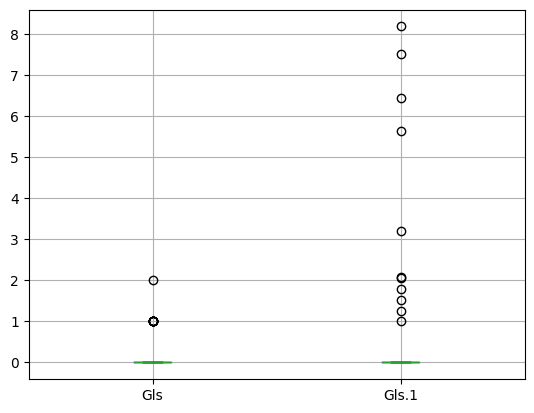

In [ ]:
df_canteranos = df[df['Min'] < 90]
boxplot = df_canteranos.boxplot(column=['Gls', 'Gls.1'])

En la representación de arriba, vemos como un jugador que no jugó mucho tiene una media de más de 8 goles cada 90 minutos, es un atípico enorme. En general, es atípico que marquen goles.

Vamos a borrar las filas que tienen pos = GK y las que han jugado menos de 90 minutos:

In [ ]:
df_filtrado = df[(df['Pos'] != 'GK') & (df['Min'] >= 90)]
print(f"Quedan {df_filtrado.shape[0]} jugadores después del filtrado.")

Quedan 2290 jugadores después del filtrado.


Ahora, hay tres valores nulos en toda la base de datos: la nacionalidad de un jugador y la edad/año de nacimiento de otros dos. Vamos a descartarlos, dado que son una enana parte de la muestra:

In [ ]:
df_filtrado = df_filtrado.dropna()
print(f"Quedan {df_filtrado.shape[0]} jugadores tras eliminar los valores nulos.")

Quedan 2287 jugadores tras eliminar los valores nulos.


Lo mejor sería tratar a cada fila como si fuese un jugador distinto. ¿Por qué? Porque cambiar de equipo puede cambiar tu posición habitual, tu liga (en la Bundesliga se marca muchas más veces por partido, por ejemplo) y tu estado de ánimo (un jugador descontento cambia de club y empieza a rendir en su nuevo club). No queremos, entonces, conocer al jugador y vamos a borrar todo lo que lo identifique.

Tras haber sido transformado a un CSV, hemos perdido información a la que podríamos acceder desde la página web: enlaces en el nombre de los jugadores que nos permitían acceder a un perfil de la página del jugador con más información, lo cual ocurre también con la selección, el equipo y la liga, y la razón por la que se ha escogido esa nacionalidad para el jugador.

Otro dato que perdemos es el enlace que te conecta a los partidos que ha jugado en esa temporada el jugador. Si quisiésemos recuperar el enlace, en el caso de Brenden Aaronson, tendríamos que reconstruirlo usando el atributo de la última columna, la temporada que queremos mirar (en nuestro caso 2025-2026) y su nombre separado por guiones para poder ver todos los partidos que jugó durante la temporada. (https://fbref.com/en/players/5bc43860/matchlogs/2025-2026/summary/Brenden-Aaronson-Match-Logs)

Ahora que sabemos que estas columnas no nos sirven para modelar, podemos borrar las columnas _Matches_ y _-9999_.

Un dato más que no nos sirve es _Rk_, un dato usado dentro de la página web para ver el la posición del jugador cuando estás ordenando dependiendo de un dato (si ordenas por más partidos jugados, _Rk_ se actualiza en la página web). Es decir, es un índice, no lo queremos.

**Vamos a borrar esas tres columnas:**

In [ ]:
df_filtrado = df_filtrado.drop(columns=['Rk', 'Matches', '-9999'])
df_filtrado.head()

,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,...,G-PK,PK,PKatt,CrdY,CrdR,Gls.1,Ast.1,G+A.1,G-PK.1,G+A-PK
0,Brenden Aaronson,us USA,MFFW,Leeds United,eng Premier League,24.0,2000.0,37,30,2449,...,4,0,0,3,0,0.15,0.18,0.33,0.15,0.33
2,Zach Abbott,eng ENG,DF,Nottingham,eng Premier League,19.0,2006.0,3,2,164,...,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00
3,Jones El-Abdellaoui,ma MAR,MFFW,Celta Vigo,es La Liga,19.0,2006.0,22,4,681,...,2,0,0,0,0,0.26,0.00,0.26,0.26,0.26
4,Himad Abdelli,dz ALG,MF,Marseille,fr Ligue 1,25.0,1999.0,8,1,138,...,0,0,0,1,0,0.00,0.00,0.00,0.00,0.00
5,Himad Abdelli,dz ALG,MF,Angers,fr Ligue 1,25.0,1999.0,13,11,943,...,0,2,2,1,0,0.19,0.00,0.19,0.00,0.00


Más cosas que no queremos son el nombre, la nación y el equipo. El nombre no lo queremos porque identifica al jugador, y la nación y el equipo nos forzaría a añadir muchísimas variables dummy (~110 naciones y 96 equipos distintos). No queremos sufrir de maldición de la dimensionalidad así que vamos a excluirlas también.

**Borremos otras tres columnas:**

In [ ]:
df_filtrado = df_filtrado.drop(columns=['Player', 'Nation', 'Squad'])
df_filtrado.head()

,Pos,Comp,Age,Born,MP,Starts,Min,90s,Gls,Ast,...,G-PK,PK,PKatt,CrdY,CrdR,Gls.1,Ast.1,G+A.1,G-PK.1,G+A-PK
0,MFFW,eng Premier League,24.0,2000.0,37,30,2449,27.2,4,5,...,4,0,0,3,0,0.15,0.18,0.33,0.15,0.33
2,DF,eng Premier League,19.0,2006.0,3,2,164,1.8,0,0,...,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00
3,MFFW,es La Liga,19.0,2006.0,22,4,681,7.6,2,0,...,2,0,0,0,0,0.26,0.00,0.26,0.26,0.26
4,MF,fr Ligue 1,25.0,1999.0,8,1,138,1.5,0,0,...,0,0,0,1,0,0.00,0.00,0.00,0.00,0.00
5,MF,fr Ligue 1,25.0,1999.0,13,11,943,10.5,2,0,...,0,2,2,1,0,0.19,0.00,0.19,0.00,0.00


Cambiemos el formato con el que guardamos la *Pos* y la *Comp*:

En el caso de *Comp*, vamos a hacer *one hot encoding* porque queremos saber a que liga pertenece cada jugador, y queremos guardarlo en algo que no sea un string.

En el de *Pos* lo que haremos es convertirla en una binaria, queremos saber si el jugador juega de delantero (tiene FW o alguna combinación que lo incluya) o no. Arriba hemos visto que los que contienen *foward* son FW, MFFW, FWMF y DFFW, serán 1. El resto serán 0.

Hagamos las transformaciones:

In [ ]:
df_filtrado = pd.get_dummies(df_filtrado, columns=['Comp'], dtype=int, drop_first=True) # perdemos bundesliga
# pero si no perteneces a ninguna de las cuatro ligas representadas por el dummy, eres de la bundesliga
# no pierdes info ni eres redundante asi
df_filtrado.head()

,Pos,Age,Born,MP,Starts,...,G+A-PK,Comp_eng Premier League,Comp_es La Liga,Comp_fr Ligue 1,Comp_it Serie A
0,MFFW,24.0,2000.0,37,30,...,0.33,1,0,0,0
2,DF,19.0,2006.0,3,2,...,0.00,1,0,0,0
3,MFFW,19.0,2006.0,22,4,...,0.26,0,1,0,0
4,MF,25.0,1999.0,8,1,...,0.00,0,0,1,0
5,MF,25.0,1999.0,13,11,...,0.00,0,0,1,0


In [ ]:
df_filtrado['Rol_Ofensivo'] = df_filtrado['Pos'].str.contains('FW').astype(int)
display(df_filtrado[['Pos', 'Rol_Ofensivo']].value_counts()) # comprobando si estan bien asignados
# los tres delantero-defensas han sido excluidos por ser canteranos o por valores faltantes, una de dos
print(df_filtrado['Rol_Ofensivo'].value_counts()) # veamos cuantos tenemos de cada tipo

,,count
Pos,Rol_Ofensivo,
MF,0,787
DF,0,625
FW,1,294
MFFW,1,216
DFMF,0,129
FWMF,1,121
MFDF,0,115


Rol_Ofensivo
0    1656
1     631
Name: count, dtype: int64


In [ ]:
# ahora que hemos visto que esta bien, borramos la variable pos
df_filtrado = df_filtrado.drop(columns=['Pos'])

Por último, tenemos que pensar cuáles de las variables redundantes queremos borrar. Quitaremos cuatro selectas: *Born*, *90s*, *G+A* y *G+A.1*, porque son combinaciones lineales exactas. Otras, que se van a conservar, también lo son, pero las conservamos para ver cuál preferimos después de hacer otro filtrado o una regularización.

In [ ]:
df_filtrado = df_filtrado.drop(columns=['Born', '90s', 'G+A', 'G+A.1'])

Nuestra base de datos termina quedando así, después de todo esto:

In [ ]:
df_filtrado.head()

,Age,MP,Starts,Min,Gls,Ast,G-PK,PK,PKatt,CrdY,CrdR,Gls.1,Ast.1,G-PK.1,G+A-PK,Comp_eng Premier League,Comp_es La Liga,Comp_fr Ligue 1,Comp_it Serie A,Rol_Ofensivo
0,24.0,37,30,2449,4,5,4,0,0,3,0,0.15,0.18,0.15,0.33,1,0,0,0,1
2,19.0,3,2,164,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,1,0,0,0,0
3,19.0,22,4,681,2,0,2,0,0,0,0,0.26,0.00,0.26,0.26,0,1,0,0,1
4,25.0,8,1,138,0,0,0,0,0,1,0,0.00,0.00,0.00,0.00,0,0,1,0,0
5,25.0,13,11,943,2,0,0,2,2,1,0,0.19,0.00,0.00,0.00,0,0,1,0,0


In [ ]:
print(f"Disponemos de {df_filtrado.shape[0]} jugadores y {df_filtrado.shape[1]} atributos.")

Disponemos de 2287 jugadores y 20 atributos.


Hemos reducido bastantes dimensiones, teniendo en cuenta que luego vamos a quitar más.

## 1.5 EDA

Antes de empezar con el EDA, tenemos que hacer un paso esencial: crear *train*, *test* y *val*.

In [ ]:
#blablabla

---

#2 blablabla

-------------------------------------------------------------------------------------------------------------------------------

to do, tareas

lo que ponga en el md, supongo